<a href="https://colab.research.google.com/github/csbell-vu/attention-exploration/blob/main/05_intro_tokenizers_workbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# From Transformers to LLMs: Tokenizers

**Learning Outcomes**:
* Understand the role of tokenizers in supporting natural language processing
* Conceptual understanding of types of tokenizers
* Consequences of tokenizer choice

***

## Transformers: Numbers and Words

![Transformers need additional help to actually use text by using the tokenizer.](https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter2/full_nlp_pipeline.svg)

Tokenizers:
* Are not actually connected to the transformer or LLM, and are defined separately
* Define the entire scope of vocabulary and expression that is possible from an LLM
* Can be trained alongside an LLM for additional token representations or changes

## Demonstrative Example

<font color="blue">
<strong>
Strong suggestion: if you're using Google Colab, try to choose a GPU runtime to accelerate the code below. Otherwise, you will have graduated and already be employed by the time some of this code runs.
</strong>
</font>
<font color="blue">
<strong>
✨ You're welcome. ✨
</strong>

</font>

In [ ]:
# First, let's install what we need (uncomment if needed)
# !pip install transformers datasets torch accelerate

### Tokenizers: Before we even get to the model

Let's actually run some text through these models and see how the words become numbers to be entered into the model.

Basic Behavior:
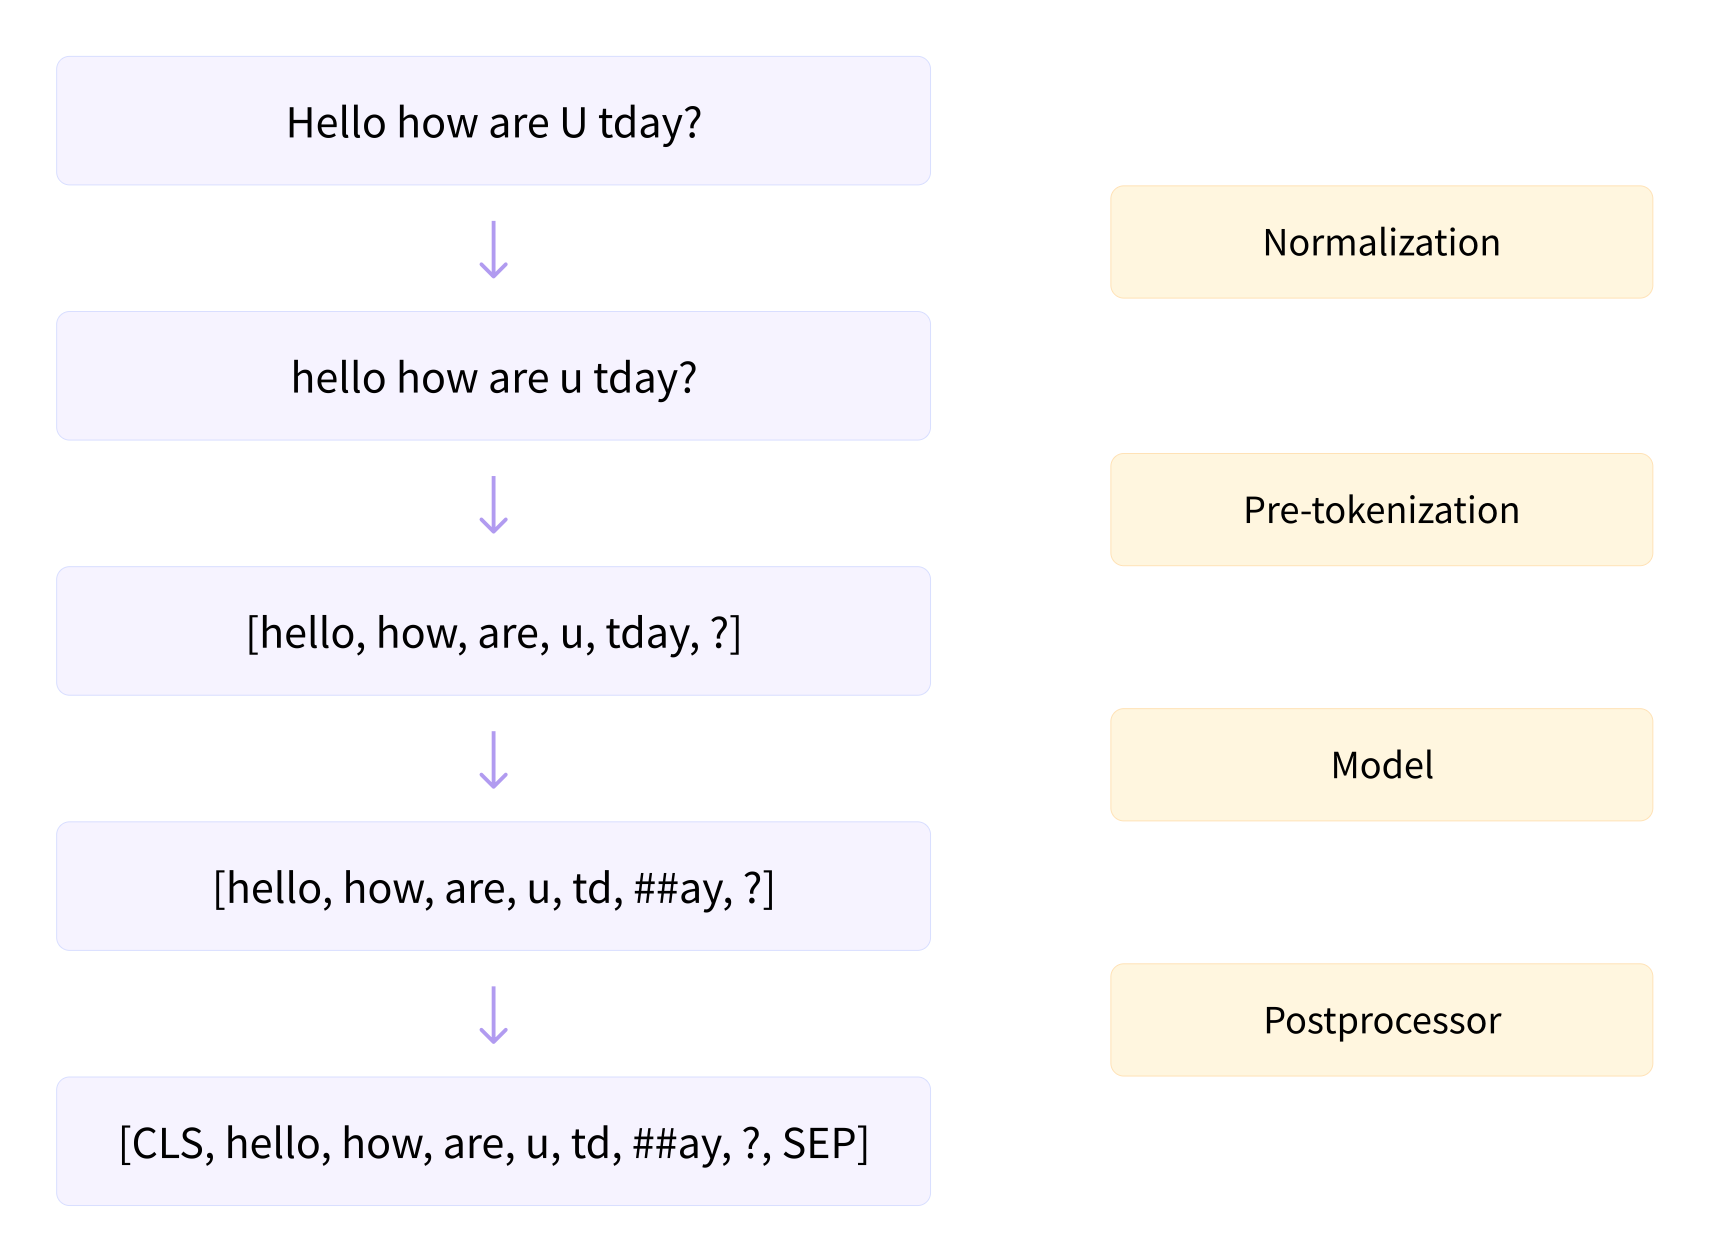

In [ ]:
from transformers import AutoTokenizer
from itertools import islice

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

In [ ]:
# Tokenize some text
text = # add your text here
inputs = tokenizer(text, return_tensors='pt')

# Uncomment to view inputs
#inputs

#### Attention Mask

In [ ]:
# verify attention mask by adding padding
pad_inputs = tokenizer(text, return_tensors = "pt", padding='max_length', truncation=True)

# Uncomment to view padded inputs
#pad_inputs

#### Input IDs

In [ ]:
# convert input ids to tokens
input_ids = # add expression here
tokenizer.convert_ids_to_tokens(input_ids)

In [ ]:
# length
len(input_ids)

In [ ]:
# is the conversion back to tokens the same?
print(f'The original text was: **{text}**')
print(f'The direct conversion of the input IDs to text is:')

tokenizer.convert_ids_to_tokens(input_ids)

#### Special Tokens

In [ ]:
spec_tok = tokenizer.all_special_tokens
spec_ids = tokenizer.all_special_ids

# All Special Tokens: Uncomment to view
#print('Special tokens: ', spec_tok)
#print('Special ids: ', spec_ids)

#### The Vocabulary
The vocabulary defines the extent of all possible words that can be created by the transformer, including the special tokens.

In [ ]:
#learn about the vocabulary
len(tokenizer.vocab)

In [ ]:
# preview some of the dictionary
dict(islice(tokenizer.vocab.items(), 0, 20))

A question will follow - use the following 3 cases of `novocab_text` to explore.

In [ ]:
novocab_text = "As a philosophy major, I love to study the ancient Phoenician ecclesiastical texts."
#novocab_text = "The genome's coded information within the DNA is first transcribed into messenger RNA (mRNA) via RNA polymerase, and subsequently translated into functional polypeptides (proteins) by ribosomes in the cytoplasm, a highly conserved process fundamental to maintaining cellular homeostasis across all domains of life"
#novocab_text = "I found it - the missing piece of the 🧩!"

# create the idstok
novocab_ids = tokenizer(novocab_text).input_ids

# Convert novocab_ids back to text
toks = tokenizer.convert_ids_to_tokens(novocab_ids)

# Uncomment to view tokens
#toks

Note the two ampersands breaking down the `Phoenician` into multiple tokens. This relationship must be learned. Compare this idea to the knowledge content of a single token `Phoenician` and requirements for learning there.


In [ ]:
# Reconstruct the actual sentence
tostring = tokenizer.convert_tokens_to_string(toks)
print(tostring)

# True reconstruction using decoding(ish)
tokenizer.decode(novocab_ids, skip_special_tokens=True, clean_up_tokenization_spaces=True)

In [ ]:
tokenizer.batch_decode(novocab_ids)

### **Thinking about the impact of Tokenization**
Consider the following scenarios:

#### A: Multiple tokens or one token?
You are a biology major trying to use this model to do anything whatsoever, and consider the representation above regarding how text is tokenized and how it is split. Consider alternately a model that has a single representation for the whole word. Considered in "the limit" or extreme cases and thinking about attention, what effect do you think tokenization has on the ability for a transformer to perform in such an area?

#### B. Role of the Unknown token
Consider yet even further the unknown token. Imagine now you're trying to classify user emotion based on the usage of emojis. How might the unknown token affect the performance of the model?

### About Tokenization Strategies, Briefly

| Tokenization Strategy | Brief Description | Pros | Cons | Example Models (using this strategy) |
|----------------------|------------------|------|------|--------------------------------------|
| **Byte-Pair Encoding (BPE)** | Subword algorithm that starts from characters/words and iteratively merges frequent symbol pairs to grow vocabulary. Balances granularity and vocabulary size.  | - Supports new/rare words via subword splits<br>- Smaller vocab than pure word tokenizers<br>- Efficient for many languages | - Might still produce unknown tokens if symbol not in vocab<br>- Merge choices based on frequency, not likelihood | GPT-2, RoBERTa (BPE variant), XLM, FlauBERT (with rule-based pretokenization)|
| **WordPiece** | Similar to BPE but selects subword merges that **maximize likelihood** of training data rather than just frequency.  | - Better modeling of training distribution<br>- Often yields robust segmentation | - Computationally more complex to train than plain BPE | BERT, DistilBERT, Electra|
| **Unigram (via SentencePiece)** | Starts with a large initial vocabulary and **prunes tokens based on a probabilistic model**, keeping the most likely subwords. | - Flexible segmentation options<br>- Probabilistically driven leads to meaningful subwords | - Not directly used standalone in Transformers (paired with SentencePiece) | (Underlying algorithm) SentencePiece models e.g., ALBERT, XLNet, Marian, T5 |
| **SentencePiece (BPE/Unigram)** | Language-independent tokenizer that treats text as a **raw stream** (including spaces), then applies either BPE or unigram training. Designed to handle languages without clear word boundaries. | - Works well for languages without explicit spaces<br>- Removes reliance on external pretokenization | - Slightly more complex decoding (space marker handling) | XLNet, ALBERT, Marian, T5 (using SentencePiece + Unigram) |

Source: [Summary of the Tokenizers, Huggingface Course](https://huggingface.co/docs/transformers/en/tokenizer_summary)


### Rest of the generation

In [ ]:
import torch
from transformers import BertForMaskedLM

In [ ]:
bert_base = BertForMaskedLM.from_pretrained('bert-base-cased')

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

In [ ]:
# define your own text below as mlm_text
#mlm_text = "The cat jumped [MASK] the table."
mlm_inputs = tokenizer(mlm_text, return_tensors='pt')

In [ ]:
# Run through base BERT with forward pass
with torch.no_grad():
    outputs = bert_base(**mlm_inputs, output_hidden_states=True)

In [ ]:
# What did we get?
outputs.keys()

In [ ]:
# look at hidden states
# len(outputs.hidden_states)

In [ ]:
# look at last hidden state
outputs.hidden_states[-1].shape

In [ ]:
outputs.logits

Do the prediction

In [ ]:
# Get logits for the [MASK] token (usually at the last position if appended)
logits = outputs.logits
masked_token_index = torch.where(mlm_inputs["input_ids"] == tokenizer.mask_token_id)[1]
mask_logits = logits[0, masked_token_index, :] # Logits for the masked position

# 5. Apply Softmax & 6. Find Top Predictions
probabilities = torch.softmax(mask_logits, dim=-1)
top_k = torch.topk(probabilities, k=5) # Get top 5 predictions

In [ ]:
# look at topk
top_k

In [ ]:
# 7. Decode Tokens
predicted_tokens = top_k.indices.tolist()
predicted_words = tokenizer.batch_decode(predicted_tokens)

In [ ]:
# look at predicted words
# predicted_words

<font color='red'><strong>What.....what's that output there?</strong></font>

In [ ]:
# ADD THIS
predicted_words[0].split(' ')
predicted_tokens

In [ ]:
# ADD THIS
import pandas as pd
pd.DataFrame(list(zip(predicted_words[0].split(' '), top_k.values.tolist()[0])), columns=['Word', 'Probability'])

## Summary

What we've seen:

1. **Transformer architecture is real** - we can see the layers, attention heads, Q/K/V projections

2. **BERT vs GPT-2** - encoder vs decoder, but same fundamental building blocks

3. **Heads are modular** - same base transformer, different heads for different tasks

4. **Transfer learning works** - the head is tiny compared to the body
